In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import warnings
warnings.filterwarnings('ignore')

# Dataset Loading¶
In this section, we locate the dataset files available in the Kaggle environment. This step helps us identify the file path before loading the SMS Spam Collection dataset into our project.



In [2]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.lower().endswith('.csv'):
            print(os.path.join(dirname, filename))

/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv


# Loading the Dataset
In this step, we load the SMS Spam Collection dataset using Pandas. The dataset contains SMS messages labeled as either spam or ham. We will use these messages to build our binary classification model.

In [3]:
df = pd.read_csv("/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv", encoding="latin-1")

df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


# Data Exploration
In this section, we will explore the dataset structure, column names, and missing values to understand the data before preprocessing.

In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (5572, 5)

Column Names:
Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB

Missing Values:
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64


# Data Cleaning and Preprocessing
In this section, we will remove unnecessary columns, keep the SMS labels and message text, and convert the labels into numerical values for Logistic Regression.

In [5]:
# Keep only the required columns
df = df[['v1', 'v2']].copy()

# Rename columns
df.columns = ['label', 'message']

# Convert labels into numerical values
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

# Display the cleaned dataset
print(df.head())

print("\nClass Distribution:")
print(df['label'].value_counts())

   label                                            message
0      0  Go until jurong point, crazy.. Available only ...
1      0                      Ok lar... Joking wif u oni...
2      1  Free entry in 2 a wkly comp to win FA Cup fina...
3      0  U dun say so early hor... U c already then say...
4      0  Nah I don't think he goes to usf, he lives aro...

Class Distribution:
label
0    4825
1     747
Name: count, dtype: int64


# Train-Test Split
In this section, we will split the dataset into training and testing sets. We will use 80% of the data for training and 20% for testing while maintaining the same class distribution.

In [6]:
X = df['message']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4457
Testing samples: 1115


# Text Vectorization using TF-IDF
In this section, we will convert SMS messages into numerical features using TF-IDF. This allows the Logistic Regression model to process text data. We will fit the vectorizer on the training data and apply it to the testing data.

In [7]:
tfidf = TfidfVectorizer(max_features=3000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Logistic Regression Model¶
In this section, we will implement Logistic Regression from scratch. We will define the Sigmoid function to calculate probabilities and the Binary Cross-Entropy Loss to measure prediction errors. These functions will be used by all five optimization algorithms.

In [8]:
# Sigmoid Function
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


# Binary Cross-Entropy Loss
def compute_loss(y_true, y_pred):
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )

    return loss


# Calculate Gradients
def compute_gradients(X, y, weights, bias):
    n = X.shape[0]

    predictions = sigmoid(X @ weights + bias)
    errors = predictions - y

    dw = np.asarray(X.T @ errors).ravel() / n
    db = np.mean(errors)

    return dw, db

# Mini-batch Gradient Descent with Momentum

In this section, we will implement Mini-batch Gradient Descent with Momentum to train the Logistic Regression model and minimize the Binary Cross-Entropy Loss.

In [9]:
def train_minibatch_momentum(X, y, learning_rate=0.01,
                             momentum=0.9, epochs=100,
                             batch_size=32):

    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0.0

    velocity_w = np.zeros(n_features)
    velocity_b = 0.0

    losses = []

    for epoch in range(epochs):

        indices = np.random.permutation(n_samples)
        X_shuffled = X[indices]
        y_shuffled = y[indices]

        for start in range(0, n_samples, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            dw, db = compute_gradients(
                X_batch, y_batch, weights, bias
            )

            velocity_w = momentum * velocity_w + learning_rate * dw
            velocity_b = momentum * velocity_b + learning_rate * db

            weights -= velocity_w
            bias -= velocity_b

        predictions = sigmoid(X @ weights + bias)
        loss = compute_loss(y, predictions)
        losses.append(loss)

    return weights, bias, losses

In [10]:
weights_mb, bias_mb, losses_mb = train_minibatch_momentum(
    X_train_tfidf,
    y_train.to_numpy(),
    learning_rate=0.01,
    momentum=0.9,
    epochs=100,
    batch_size=32
)

print("Final Training Loss:", losses_mb[-1])

Final Training Loss: 0.13368166171673182



# Model Evaluation

In this section, we evaluate the performance of the Mini-batch Gradient Descent with Momentum optimizer using the test dataset. We calculate Accuracy, Precision, Recall, F1 Score, and Binary Cross-Entropy Loss to measure the model's classification performance.


In [11]:
y_test_array = y_test.to_numpy()

y_prob_mb = sigmoid(X_test_tfidf @ weights_mb + bias_mb)
y_pred_mb = (y_prob_mb >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test_array, y_pred_mb))
print("Precision:", precision_score(y_test_array, y_pred_mb, zero_division=0))
print("Recall:", recall_score(y_test_array, y_pred_mb, zero_division=0))
print("F1 Score:", f1_score(y_test_array, y_pred_mb, zero_division=0))
print("Test Loss:", compute_loss(y_test_array, y_prob_mb))

Accuracy: 0.9605381165919282
Precision: 0.9906542056074766
Recall: 0.7114093959731543
F1 Score: 0.828125
Test Loss: 0.1384138248306915



# Confusion Matrix

In this section, we use a Confusion Matrix to evaluate the classification results. It shows the number of correctly and incorrectly classified messages as Ham or Spam.


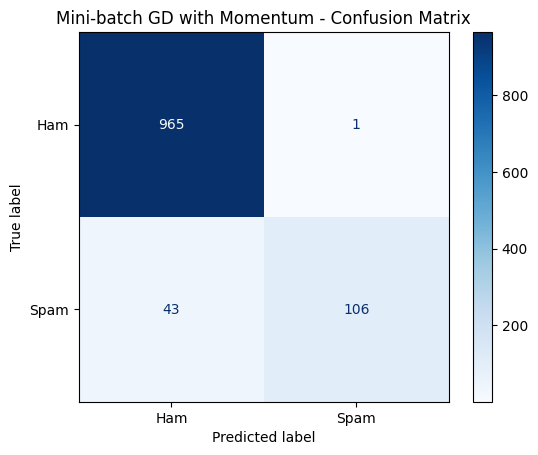

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test_array, y_pred_mb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Ham', 'Spam']
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Mini-batch GD with Momentum - Confusion Matrix')
plt.show()


# Evaluation Metrics Bar Chart

In this section, we visualize the model's evaluation metrics using a bar chart. This helps us compare Accuracy, Precision, Recall, and F1 Score and understand the model's classification performance.


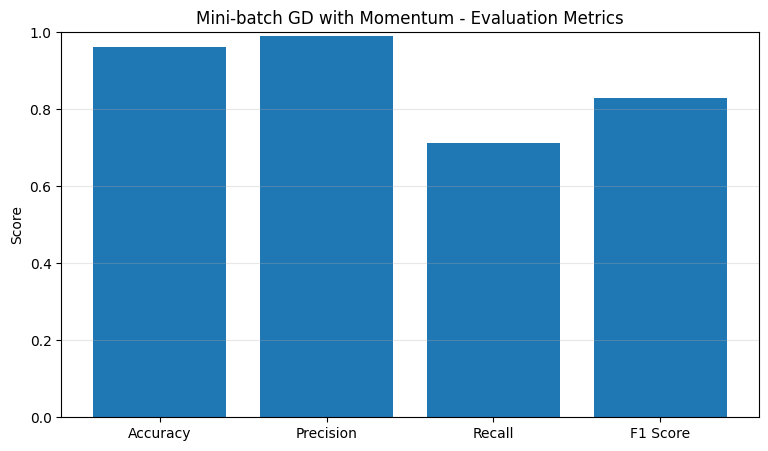

In [13]:
metrics = {
    'Accuracy': accuracy_score(y_test_array, y_pred_mb),
    'Precision': precision_score(y_test_array, y_pred_mb, zero_division=0),
    'Recall': recall_score(y_test_array, y_pred_mb, zero_division=0),
    'F1 Score': f1_score(y_test_array, y_pred_mb, zero_division=0)
}

plt.figure(figsize=(9, 5))
plt.bar(metrics.keys(), metrics.values())
plt.title('Mini-batch GD with Momentum - Evaluation Metrics')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.3)
plt.show()


# Actual vs Predicted Distribution

In this section, we compare the actual distribution of Ham and Spam messages with the predicted distribution produced by the Mini-batch Gradient Descent with Momentum model. This visualization helps us understand how well the model identifies each class.


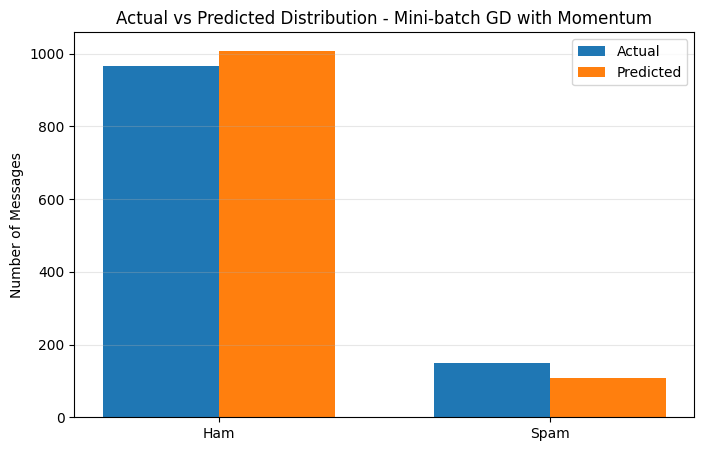

In [14]:
actual_counts = pd.Series(y_test_array).value_counts().sort_index()
predicted_counts = pd.Series(y_pred_mb).value_counts().sort_index()

labels = ['Ham', 'Spam']
x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, actual_counts.reindex([0, 1], fill_value=0),
        width, label='Actual')

plt.bar(x + width/2, predicted_counts.reindex([0, 1], fill_value=0),
        width, label='Predicted')

plt.xticks(x, labels)
plt.ylabel('Number of Messages')
plt.title('Actual vs Predicted Distribution - Mini-batch GD with Momentum')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()


# Training Loss Curve

In this section, we visualize the Binary Cross-Entropy Loss over the training epochs. The loss curve helps us observe how the Mini-batch Gradient Descent with Momentum optimizer learns and minimizes the prediction error during training.


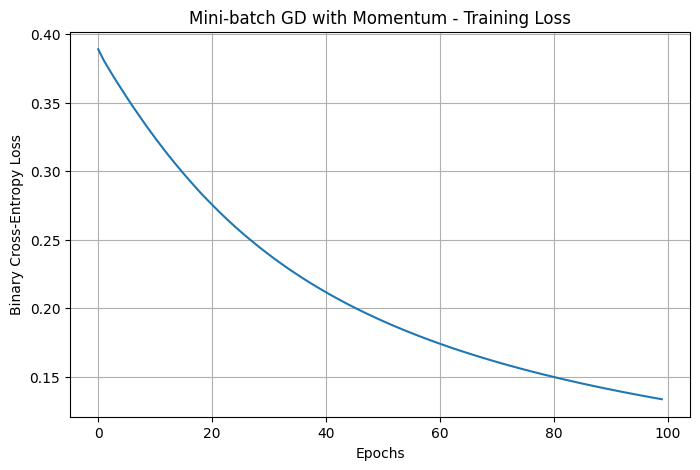

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(losses_mb)

plt.title('Mini-batch GD with Momentum - Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Binary Cross-Entropy Loss')

plt.grid(True)
plt.show()

# Results Summary Table

In this section, we summarize the Mini-batch Gradient Descent with Momentum optimizer settings and its evaluation results. The table provides an overview of the training configuration and the model's performance on the test dataset.


In [16]:
results = {
    'Parameter': [
        'Optimizer',
        'Learning Rate',
        'Momentum',
        'Epochs',
        'Batch Size',
        'Training Loss',
        'Test Loss',
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score'
    ],
    'Value': [
        'Mini-batch GD with Momentum',
        0.01,
        0.9,
        100,
        32,
        losses_mb[-1],
        compute_loss(y_test_array, y_prob_mb),
        accuracy_score(y_test_array, y_pred_mb),
        precision_score(y_test_array, y_pred_mb, zero_division=0),
        recall_score(y_test_array, y_pred_mb, zero_division=0),
        f1_score(y_test_array, y_pred_mb, zero_division=0)
    ]
}

pd.DataFrame(results)

,Parameter,Value
0,Optimizer,Mini-batch GD with Momentum
1,Learning Rate,0.01
2,Momentum,0.9
3,Epochs,100
4,Batch Size,32
5,Training Loss,0.133682
6,Test Loss,0.138414
7,Accuracy,0.960538
8,Precision,0.990654
9,Recall,0.711409
